# Data Science w Pythonie — Zajęcia 3

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kubzal/wsb-merito/blob/main/notebooks/semestr_zimowy_2026_27/data_science_w_pythonie/zajecia_3.ipynb)

Pełne notatki do zajęć znajdziesz na [stronie przedmiotu](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/data_science_w_pythonie/zajecia_3/). Ten notebook zawiera wszystkie przykłady z notatek, gotowe do uruchomienia.


## Eksploracyjna analiza danych i wizualizacja

Dane są wczytane i wyczyszczone. Kusi, żeby od razu wrzucić je do modelu — i to
jest błąd, który popełnia prawie każdy na początku. Zanim cokolwiek policzysz,
trzeba dane **obejrzeć**: jak rozkładają się wartości, co jest typowe, co
odstaje i czym różnią się grupy, które nas interesują.

Ten etap nazywa się **eksploracyjną analizą danych** (*EDA, exploratory data
analysis*), a jego głównym narzędziem jest wykres. Tabela z tysiącem liczb nie
mówi nic. Ten sam tysiąc liczb na histogramie mówi wszystko w dwie sekundy.

Po dzisiejszych zajęciach będziesz w stanie:

- narysować histogram, wykres pudełkowy, słupkowy i punktowy w matplotlib
  i seaborn,
- odczytać z histogramu kształt rozkładu i wyjaśnić, dlaczego średnia różni się
  od mediany,
- odczytać wykres pudełkowy i wskazać wartości odstające,
- porównać dwie grupy klientów wykresem i tabelą krzyżową,
- policzyć korelacje, narysować je jako mapę ciepła i wiedzieć, czego korelacja
  **nie** mówi.

> ℹ️ **Gdzie jesteśmy**
>
> W workflow projektu z pierwszych zajęć to punkt 4 — eksploracja. Ćwiczymy na
> danych siłowni, które wyczyściłeś dwa tygodnie temu. W zadaniu dostaniesz
> nowy zbiór — kredyty bankowe — i za godzinę na
> [Uczeniu głębokim](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/zajecia_3/) trafi on do modelu.
> To, co dziś zobaczysz na wykresach, powie Ci, czego się po tym modelu
> spodziewać.


## Plan na dziś

| Blok | Czas |
|---|---|
| Po co EDA i pierwszy wykres | 8 min |
| Jedna zmienna — histogram, wykres pudełkowy, słupki | 15 min |
| Dwie zmienne — porównanie grup, tabela krzyżowa, wykres punktowy | 12 min |
| Korelacja i mapa ciepła | 7 min |
| Dobre praktyki i ściągawka | 3 min |
| **Zadanie 3** | **45 min** |


## Po co EDA

EDA zaczyna się od **pytań**, nie od wykresów. Dla danych siłowni naturalne
pytania to:

1. Kim są nasi klienci? Ile mają lat, jak często przychodzą, jaki mają karnet?
2. Czy coś w danych wygląda podejrzanie?
3. **Czym różnią się klienci, którzy zrezygnowali, od tych, którzy zostali?**

Trzecie pytanie jest najważniejsze, bo to dokładnie to, czego za chwilę będzie
się uczył model. Jeśli na wykresie nie widać żadnej różnicy między grupami —
model też jej prawdopodobnie nie znajdzie.

### Dane, na których pracujemy

Wczytujemy wzorcową, wyczyszczoną wersję danych siłowni z zajęć 2:

In [1]:
import pandas as pd

URL = "https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/dane/silownia_czyste.csv"
df = pd.read_csv(URL)
df.describe().round(1)

,wiek,oplata_mies,staz_mies,wizyty_mies,zgloszenia,zrezygnowal
count,1484.0,1484.0,1484.0,1484.0,1484.0,1484.0
mean,33.3,130.5,31.2,6.5,0.8,0.2
std,9.5,38.5,17.2,3.8,0.9,0.4
min,16.0,79.0,1.0,0.4,0.0,0.0
25%,26.8,99.0,17.0,3.7,0.0,0.0
50%,33.0,129.0,32.0,5.9,1.0,0.0
75%,40.0,139.0,46.0,8.7,1.0,0.0
max,69.0,199.0,60.0,25.0,5.0,1.0


`describe()` znasz od pierwszych zajęć. To dobry start, ale 48 liczb naraz
trudno ogarnąć wzrokiem — i nie odpowiadają one na pytanie 3. Pora na wykresy.

### Narzędzia: matplotlib i seaborn

W Pythonie rysuje się głównie dwiema bibliotekami. Obie są w Colabie od razu:

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

- **matplotlib** — podstawa, na której stoi wszystko inne. Daje pełną kontrolę
  nad wykresem: tytuły, osie, kolory, linie. Konwencja importu to `plt`.
- **seaborn** — nakładka na matplotlib, stworzona do pracy z DataFrame'ami.
  Jedna linijka zamiast dziesięciu, zwłaszcza przy porównywaniu grup. Konwencja
  importu to `sns`.

Do tego pandas sam potrafi narysować kolumnę metodą `.plot()` — pod spodem też
używa matplotlib.

### Pierwszy wykres

<Axes: title={'center': 'Wiek klientów'}, ylabel='Frequency'>

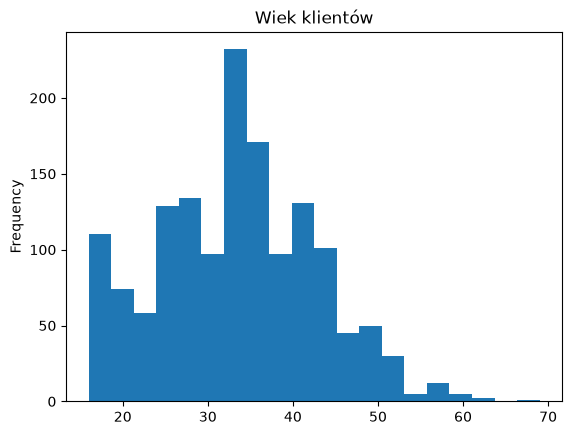

In [3]:
df["wiek"].plot(kind="hist", bins=20, title="Wiek klientów")

Większość klientów ma 20–45 lat, starszych jest coraz mniej. Ale jeden słupek
wyraźnie odstaje — przy 33 latach jest dwa razy więcej osób niż obok. Skąd?

To **my** go zrobiliśmy. Na poprzednich zajęciach uzupełniliśmy brakujący
i niemożliwy wiek medianą — a mediana wynosi 33. Ok. 60 osób dostało ten sam
wiek, stąd słupek. Pierwsza lekcja EDA: **dane pamiętają, co im zrobiłeś.**
Uzupełnianie braków zawsze zostawia ślad i dobrze jest umieć go rozpoznać.

> 💡 **Średnik na końcu linii**
>
> W Colabie nad wykresem pojawia się czasem napis w rodzaju
> `<Axes: title={'center': 'Wiek klientów'}>`. To nie błąd, tylko wartość
> zwrócona przez ostatnią linijkę komórki. Żeby go ukryć, dopisz na końcu
> `plt.show()` albo postaw średnik po ostatniej linijce.


## Jedna zmienna

### Histogram — jak rozkładają się wartości

Histogram dzieli zakres wartości na przedziały (*bins*) i pokazuje, ile
obserwacji wpada do każdego z nich. Narysujmy liczbę wizyt w miesiącu, tym razem
w seaborn, i dorysujmy średnią i medianę:

Text(0, 0.5, 'liczba klientów')

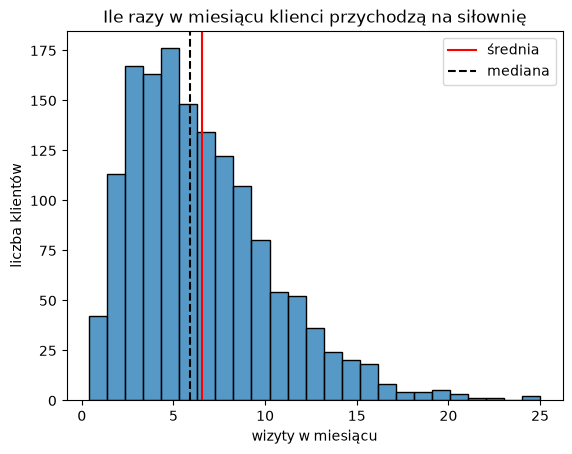

In [4]:
sns.histplot(data=df, x="wizyty_mies", bins=25)
plt.axvline(df["wizyty_mies"].mean(), color="red", label="średnia")
plt.axvline(df["wizyty_mies"].median(), color="black", linestyle="--", label="mediana")
plt.legend()
plt.title("Ile razy w miesiącu klienci przychodzą na siłownię")
plt.xlabel("wizyty w miesiącu")
plt.ylabel("liczba klientów")

Wszystkie linijki od `plt.` dotyczą **tego samego** wykresu — matplotlib dokłada
kolejne elementy do ostatnio narysowanego. `axvline` rysuje pionową linię
(*vertical line*) w podanym miejscu osi X.

Co widać:

- Typowy klient przychodzi 3–8 razy w miesiącu.
- Rozkład ma **długi ogon w prawo** — garstka osób chodzi 15–25 razy. Taki
  rozkład nazywa się **prawoskośnym**.
- **Średnia (6.55) jest większa od mediany (5.9)**, bo ogon ciągnie ją w prawo.
  Pamiętasz drogi laptop z pierwszych zajęć? To ten sam mechanizm.

Prawoskośne są prawie wszystkie dane „o ludziach i pieniądzach": zarobki, ceny
mieszkań, wartość zamówień, liczba obserwujących. Dlatego w raportach
o wynagrodzeniach GUS podaje medianę, a nie tylko średnią.

> 📝 **Ile słupków?**
>
> `bins` decyduje o tym, jak szczegółowy jest histogram. Za mało słupków
> (np. 5) — wszystko zlewa się w jedną bryłę. Za dużo (np. 200) — wykres robi
> się poszarpany i widać głównie szum. 20–30 to zwykle dobry początek;
> potem warto spróbować dwóch–trzech wartości i wybrać najczytelniejszą.

### Wykres pudełkowy — typowe wartości i odstające

Histogram pokazuje kształt rozkładu. **Wykres pudełkowy** (*boxplot*) streszcza
go do pięciu liczb i od razu wskazuje wartości odstające:

<Axes: xlabel='wizyty_mies'>

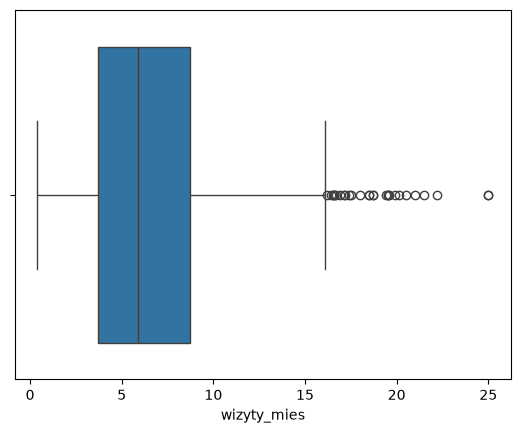

In [5]:
sns.boxplot(data=df, x="wizyty_mies")

Ten sam wykres z opisanymi elementami:

![Wykres pudełkowy liczby wizyt z opisanymi elementami](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/data_science_w_pythonie/obrazki/zajecia_3_boxplot_anatomia.png)

Jak go czytać:

- **Pudełko** to środkowe 50% klientów — od pierwszego kwartyla (Q1 = 3.7) do
  trzeciego (Q3 = 8.7). Te same liczby co `25%` i `75%` w `describe()`.
- **Kreska w pudełku** to mediana.
- **Wąsy** sięgają do najdalszych „normalnych" wartości — nie dalej niż
  półtorej długości pudełka od jego krawędzi.
- **Kółka** za wąsami to **wartości odstające** (*outliers*) — tu 28 osób, które
  chodzą na siłownię ponad 16 razy w miesiącu.

> ⚠️ **Odstająca to nie to samo co niemożliwa**
>
> Na poprzednich zajęciach wiek 230 lat zamieniliśmy na brak, bo był
> **niemożliwy**. Ktoś, kto chodzi na siłownię 20 razy w miesiącu, jest
> nietypowy, ale całkowicie prawdziwy. Wykres pudełkowy wskaże wartości
> odstające, ale to Ty decydujesz, czy to błąd, czy po prostu ciekawy
> przypadek. Domyślnie: **zostawiasz**.

### Kategorie — wykres słupkowy

Dla kolumny tekstowej histogram nie ma sensu. Liczymy wystąpienia
`value_counts()` (znasz je z pierwszych zajęć) i rysujemy jako słupki:

Text(0, 0.5, 'liczba klientów')

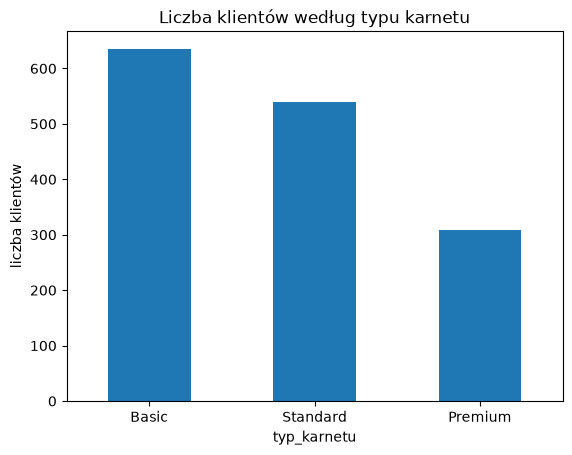

In [6]:
df["typ_karnetu"].value_counts().plot(kind="bar", title="Liczba klientów według typu karnetu")
plt.xticks(rotation=0)
plt.ylabel("liczba klientów")

`plt.xticks(rotation=0)` obraca podpisy pod słupkami do poziomu — pandas
domyślnie stawia je pionowo, co przy krótkich nazwach tylko przeszkadza.

> 📝 **A wykres kołowy?**
>
> Ludzkie oko dużo lepiej porównuje długości słupków niż kąty wycinków. Przy
> trzech kategoriach koło jeszcze ujdzie, przy sześciu już nikt nie powie, który
> wycinek jest większy. W analizie danych prawie zawsze wybieraj słupki.


## Dwie zmienne

Teraz pytanie numer 3: czym różnią się klienci, którzy odeszli?

### Liczba kontra grupa — wykresy pudełkowe obok siebie

Text(0.5, 1.0, 'Wizyty w miesiącu: zostali (0) kontra zrezygnowali (1)')

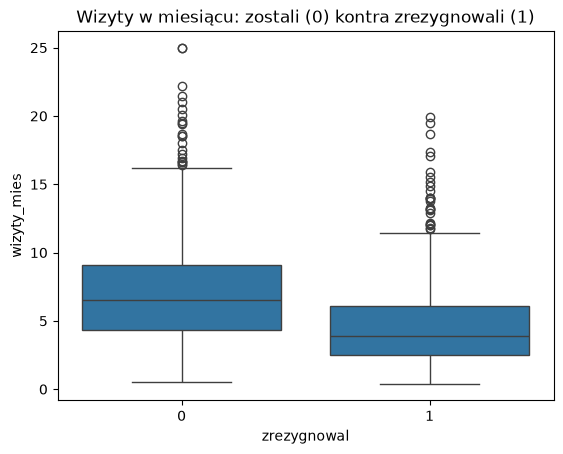

In [7]:
sns.boxplot(data=df, x="zrezygnowal", y="wizyty_mies")
plt.title("Wizyty w miesiącu: zostali (0) kontra zrezygnowali (1)")

To jest najważniejszy wykres dnia. Seaborn podzielił klientów według kolumny
`x` i dla każdej grupy narysował osobne pudełko. Różnica jest wyraźna: klienci,
którzy zrezygnowali, przychodzili rzadziej. Liczbowo możesz to sprawdzić
filtrem:

In [8]:
odeszli = df[df["zrezygnowal"] == 1]
zostali = df[df["zrezygnowal"] == 0]

print(odeszli["wizyty_mies"].median(), zostali["wizyty_mies"].median())

3.9 6.5


Mediana 3.9 wizyty kontra 6.5. Ma to sens biznesowy: kto przestaje chodzić, ten
po kilku miesiącach przestaje też płacić. **To jest cecha, z której model
będzie korzystał najbardziej** — i rzeczywiście, drzewo z zajęć 2 na Uczeniu
głębokim zadawało pytanie o wizyty jako pierwsze.

### Kategoria kontra grupa — tabela krzyżowa

Czy rezygnacje zależą od typu karnetu? Dla dwóch kolumn kategorycznych
liczymy **tabelę krzyżową** — ile klientów jest w każdej kombinacji:

In [9]:
pd.crosstab(df["typ_karnetu"], df["zrezygnowal"])

zrezygnowal,0,1
typ_karnetu,,
Basic,514,121
Premium,205,104
Standard,416,124


Liczby bezwzględne są mylące — klientów Basic jest dwa razy więcej niż Premium.
Potrzebujemy **odsetków w każdym wierszu**, czyli `normalize="index"`:

In [10]:
pd.crosstab(df["typ_karnetu"], df["zrezygnowal"], normalize="index").round(3)

zrezygnowal,0,1
typ_karnetu,,
Basic,0.809,0.191
Premium,0.663,0.337
Standard,0.770,0.230


Teraz widać: z Premium odchodzi co trzeci klient, z Basic — co piąty. Kolumnę
`1` łatwo narysować:

Text(0.5, 0, 'odsetek klientów, którzy zrezygnowali')

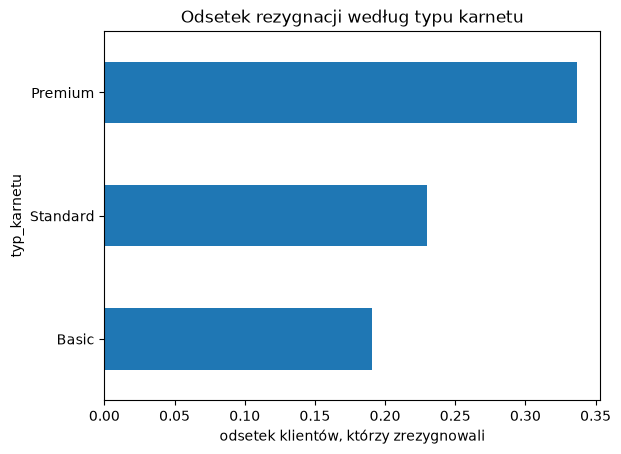

In [11]:
odsetek = pd.crosstab(df["typ_karnetu"], df["zrezygnowal"], normalize="index")[1]
odsetek.sort_values().plot(kind="barh", title="Odsetek rezygnacji według typu karnetu")
plt.xlabel("odsetek klientów, którzy zrezygnowali")

`kind="barh"` to słupki poziome — wygodne, gdy nazwy kategorii są długie.
`sort_values()` układa je od najmniejszej do największej, więc wykres czyta się
jak ranking.

> 💡 **Grupowanie na następnych zajęciach**
>
> Odsetek rezygnacji w każdej grupie to tak naprawdę **średnia** kolumny
> `zrezygnowal` (zera i jedynki) policzona osobno dla każdego karnetu. Do
> liczenia czegokolwiek „w grupach" pandas ma `groupby` — to temat kolejnych
> zajęć. Dziś wystarczy nam `crosstab`.

### Liczba kontra liczba — wykres punktowy

Dwie kolumny liczbowe pokazujemy jako chmurę punktów — każdy klient to jedna
kropka. Parametr `hue` koloruje kropki według trzeciej kolumny:

Text(0.5, 1.0, 'Staż i liczba wizyt a rezygnacja')

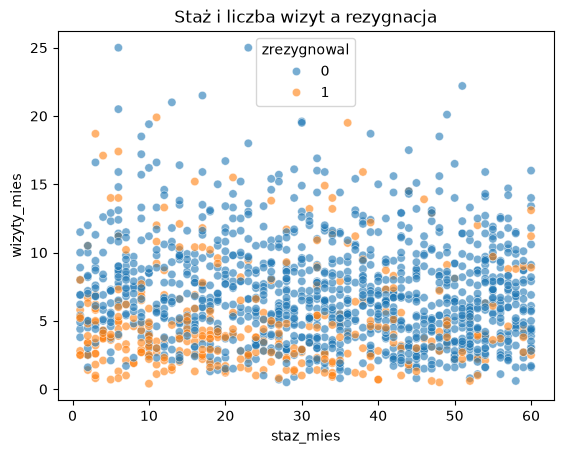

In [12]:
sns.scatterplot(data=df, x="staz_mies", y="wizyty_mies", hue="zrezygnowal", alpha=0.6)
plt.title("Staż i liczba wizyt a rezygnacja")

Pomarańczowe kropki (rezygnacje) skupiają się na dole wykresu — mało wizyt —
i trochę gęściej po lewej, przy krótkim stażu. Odchodzą głównie nowi klienci,
którzy rzadko przychodzą.

`alpha=0.6` robi kropki półprzezroczystymi. Przy 1500 punktach wiele z nich
nachodzi na siebie, a dzięki przezroczystości widać, gdzie jest ich gęsto.


## Korelacja

Zamiast oglądać wykres punktowy dla każdej pary kolumn, można policzyć jedną
liczbę — **współczynnik korelacji**. Przyjmuje wartości od −1 do 1:

| Wartość | Znaczenie |
|---|---|
| bliska **1** | gdy jedna kolumna rośnie, druga też rośnie |
| bliska **0** | brak liniowej zależności |
| bliska **−1** | gdy jedna kolumna rośnie, druga maleje |

In [13]:
korelacje = df.corr(numeric_only=True)
korelacje.round(2)

,wiek,oplata_mies,staz_mies,wizyty_mies,zgloszenia,zrezygnowal
wiek,1.00,0.02,-0.01,-0.00,0.01,-0.04
oplata_mies,0.02,1.00,-0.03,0.01,-0.04,0.13
staz_mies,-0.01,-0.03,1.00,-0.03,0.03,-0.23
wizyty_mies,-0.00,0.01,-0.03,1.00,0.01,-0.23
zgloszenia,0.01,-0.04,0.03,0.01,1.00,0.16
zrezygnowal,-0.04,0.13,-0.23,-0.23,0.16,1.00


`numeric_only=True` pomija kolumny tekstowe — korelacji miasta z wiekiem nie da
się policzyć. Tabelę liczb dużo łatwiej czytać jako **mapę ciepła**:

Text(0.5, 1.0, 'Korelacje między kolumnami liczbowymi')

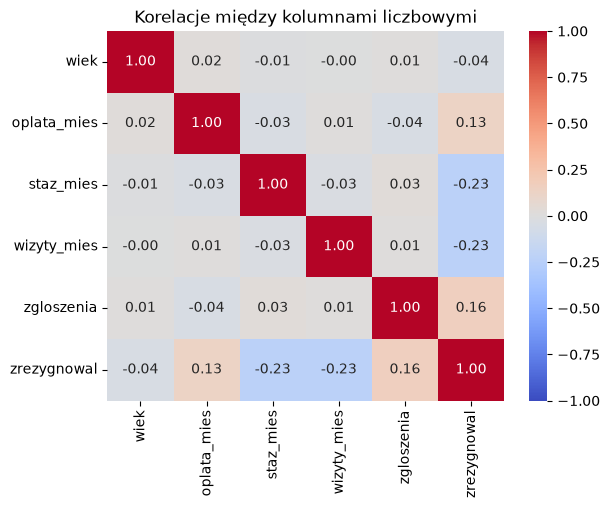

In [14]:
sns.heatmap(korelacje, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korelacje między kolumnami liczbowymi")

- `annot=True` wpisuje liczby w pola, `fmt=".2f"` zaokrągla je do dwóch miejsc.
- `cmap="coolwarm"` — czerwony dla dodatnich, niebieski dla ujemnych, szary
  dla zera.
- `vmin=-1, vmax=1` ustala skalę kolorów na pełny zakres. Bez tego seaborn
  dopasuje skalę do danych i korelacja 0.2 może wyglądać na ciemnoczerwoną.

Interesuje nas głównie **ostatni wiersz** — jak każda cecha wiąże się
z rezygnacją. Staż i wizyty: −0.23 (im więcej, tym rzadziej ktoś odchodzi).
Zgłoszenia i opłata: dodatnie (im więcej skarg i im drożej, tym częściej).
Wiek: praktycznie zero.

Przekątna to same jedynki — każda kolumna jest idealnie skorelowana sama ze
sobą. Tabela jest też symetryczna, więc wystarczy czytać połowę.

> ⚠️ **Dwie pułapki korelacji**
>
> **Korelacja mierzy tylko zależność liniową.** −0.23 brzmi słabo, a przecież
> wykres pudełkowy pokazał dużą różnicę w wizytach. Zależność jest, tylko nie
> układa się w prostą linię — szansa odejścia rośnie gwałtownie dopiero przy
> bardzo małej liczbie wizyt. Dlatego korelacja nigdy nie zastępuje wykresu.
>
> **Korelacja to nie przyczynowość.** Sprzedaż lodów i liczba utonięć są
> mocno skorelowane — bo obie rosną latem. Lody nikogo nie topią. Z samych
> danych nie wiemy, czy klienci odchodzą, **bo** przestali chodzić, czy
> przestali chodzić, **bo** już postanowili odejść.


## Dobre praktyki

Wykres w notatniku dla siebie może być byle jaki. Wykres, który ktoś inny ma
zrozumieć, musi spełniać kilka warunków:

- **Tytuł** — najlepiej taki, który mówi, co widać.
- **Podpisane osie** — z jednostką, jeśli jest (zł, mies., liczba klientów).
- **Jeden wykres — jedna wiadomość.** Lepsze trzy proste wykresy niż jeden,
  na którym jest wszystko.
- **Bez efektów 3D i bez koła** przy więcej niż kilku kategoriach.
- **Odsetki, nie liczby**, gdy porównujesz grupy różnej wielkości.

### Ściągawka

| Chcę… | Kod |
|---|---|
| zaimportować biblioteki | `import matplotlib.pyplot as plt` i `import seaborn as sns` |
| histogram | `sns.histplot(data=df, x="kol", bins=25)` |
| pionowa linia (np. średnia) | `plt.axvline(df["kol"].mean(), color="red", label="średnia")` |
| wykres pudełkowy | `sns.boxplot(data=df, x="kol")` |
| pudełka w grupach | `sns.boxplot(data=df, x="grupa", y="kol")` |
| słupki dla kategorii | `df["kol"].value_counts().plot(kind="bar")` |
| słupki poziome | `seria.plot(kind="barh")` |
| tabela krzyżowa | `pd.crosstab(df["a"], df["b"])` |
| odsetki w wierszach | `pd.crosstab(df["a"], df["b"], normalize="index")` |
| wykres punktowy z kolorem | `sns.scatterplot(data=df, x="a", y="b", hue="grupa", alpha=0.6)` |
| macierz korelacji | `df.corr(numeric_only=True)` |
| mapa ciepła | `sns.heatmap(korelacje, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)` |
| tytuł, podpisy osi, legenda | `plt.title(...)`, `plt.xlabel(...)`, `plt.ylabel(...)`, `plt.legend()` |
| wykres o innym rozmiarze | `plt.figure(figsize=(10, 4))` — **przed** rysowaniem |
| kilka wykresów w jednej komórce | `plt.show()` po każdym z nich |

## Zadanie 3

Treść zadania na dzisiejsze zajęcia znajdziesz w [notatkach](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/data_science_w_pythonie/zajecia_3/#zadanie-3-kto-nie-spaci-kredytu-6-pkt). Rozwiązanie zrób w **osobnym** notebooku i oddaj go na Moodle.